# Analisis Penjualan & Profitabilitas — Seduh Nusantara 2025

**Proyek Sertifikasi BNSP — Skema Data Analyst (SKKNI No. 299 Tahun 2020)**

| | |
|---|---|
| **Studi kasus** | Kedai kopi fiktif *Seduh Nusantara*, 6 outlet di Jabodetabek |
| **Periode data** | 1 Januari – 31 Desember 2025 |
| **Pertanyaan utama** | *Penjualan tumbuh, tetapi di mana laba bocor?* |
| **Alat** | Python (pandas, numpy, matplotlib), SQLite |

> ⚠️ **Catatan penting:** seluruh data adalah **simulasi**. Pola promo, channel, dan perilaku member
> dirancang saat data dibuat. Notebook ini menunjukkan **cara menganalisis**, bukan fakta pasar.

### Pertanyaan bisnis
1. Penjualan naik sepanjang 2025 — apakah laba ikut naik dengan kecepatan yang sama?
2. Channel, promo, atau produk mana yang menggerus margin?
3. Apa yang bisa dilakukan untuk menaikkan laba, dan berapa perkiraan dampaknya?

### Daftar isi
| No | Bagian | Unit kompetensi |
|---|---|---|
| 0 | Persiapan lingkungan | — |
| 1 | Mengumpulkan data (membuat data simulasi) | Mengumpulkan Data |
| 2 | Menelaah data mentah | Menelaah Data |
| 3 | Membersihkan & memvalidasi data | Memvalidasi Data |
| 4 | Profil data & kamus data | Menelaah Data, Menentukan Objek Data |
| 5 | Analisis: KPI, tren, outlet, channel, promo, produk, member | Mengidentifikasi Kebutuhan Data |
| 6 | Estimasi dampak rekomendasi | Menyusun Laporan Hasil Analisis |
| 7 | Verifikasi silang dengan SQL | Memvalidasi Data |
| 8 | Kesimpulan, rekomendasi, dan batasan | Menyusun Laporan Hasil Analisis |

---
## 0. Persiapan lingkungan

Memuat library, menentukan lokasi folder proyek, dan menyiapkan fungsi bantu untuk format angka Rupiah
dan persen. Notebook ini diletakkan di folder utama proyek (sejajar dengan folder `data/`, `scripts/`, `sql/`).

In [1]:
import json
import re
import sqlite3
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# Folder proyek: folder yang berisi data/ (notebook bisa dibuka dari root atau subfolder)
ROOT = Path.cwd()
if not (ROOT / "sql").exists() and (ROOT.parent / "sql").exists():
    ROOT = ROOT.parent
DATA = ROOT / "data"
DATA.mkdir(exist_ok=True)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

# Format angka gaya Indonesia
def rp(x, juta=False):
    if juta:
        return f"Rp{x / 1e6:,.1f} jt".replace(",", "X").replace(".", ",").replace("X", ".")
    return f"Rp{x:,.0f}".replace(",", ".")

def pct(x, d=1):
    return f"{x * 100:.{d}f}%".replace(".", ",")

# Gaya grafik: satu warna utama, satu warna penanda masalah
BLUE, RED, GRAY = "#2a78d6", "#e34948", "#b5b4ae"
plt.rcParams.update({
    "figure.figsize": (9, 4), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "axes.axisbelow": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.edgecolor": "#8a8984", "xtick.color": "#52514e", "ytick.color": "#52514e",
})
juta_fmt = mtick.FuncFormatter(lambda v, _: f"{v / 1e6:,.0f} jt".replace(",", "."))
pct_fmt = mtick.PercentFormatter(1.0, decimals=0)

print("Folder proyek:", ROOT.name)

Folder proyek: bnsp-data-analyst


---
## 1. Mengumpulkan data (membuat data simulasi)

Di bisnis nyata, data penjualan berasal dari **mesin kasir tiap outlet**, **ekspor aplikasi delivery**, dan
**daftar member**, lalu digabung menjadi satu tabel transaksi. Karena proyek ini memakai data simulasi,
tahap ini *meniru* hasil penggabungan tersebut.

Keluaran tahap ini (folder `data/`):

| File | Isi |
|---|---|
| `master_outlet.csv` | Tabel master 6 outlet |
| `master_produk.csv` | Tabel master 15 produk, termasuk HPP per unit |
| `raw_sales.csv` | Data transaksi mentah yang **sengaja dikotori** (bukti proses cleaning) |

`SEED` dibuat tetap, sehingga setiap kali dijalankan hasilnya **selalu sama** (reproducible).

### 1.1 Tabel master dan parameter simulasi

- **Outlet**: `share` = porsi order outlet, `growth` = kenaikan relatif Desember vs Januari di luar tren umum.
- **Produk**: `price` = harga jual, `cogs_per_unit` = HPP, `weight` = peluang dipilih di dalam grupnya.
- **Pola yang sengaja ditanam**: tren naik pelan, promo *Diskon Gajian* (tgl 25–27, diskon 15%),
  *Promo Kopi Susu Juni* (diskon 35%), porsi delivery naik 22% → 34,7%, komisi delivery 20%.
- *Diskon Gajian* tetap ada di data (ikut dalam total diskon), tetapi **tidak dianalisis sebagai temuan
  tersendiri**. Analisis promo difokuskan pada *Promo Kopi Susu Juni*.

In [2]:
SEED = 2025
rng = np.random.default_rng(SEED)

OUTLETS = pd.DataFrame(
    [
        ("SN01", "Seduh Nusantara Kemang", "Jakarta Selatan", 0.22, 0.06),
        ("SN02", "Seduh Nusantara BSD", "Tangerang Selatan", 0.19, 0.12),
        ("SN03", "Seduh Nusantara Summarecon Bekasi", "Bekasi", 0.18, 0.15),
        ("SN04", "Seduh Nusantara Margonda", "Depok", 0.16, 0.10),
        ("SN05", "Seduh Nusantara Sentul", "Bogor", 0.13, 0.02),
        ("SN06", "Seduh Nusantara Kelapa Gading", "Jakarta Utara", 0.12, -0.04),
    ],
    columns=["outlet_id", "outlet", "kota", "share", "growth"],
)

PRODUCTS = pd.DataFrame(
    [
        ("P01", "Kopi Susu Gula Aren", "Kopi", 22000, 7500, 0.200),
        ("P02", "Americano", "Kopi", 20000, 5200, 0.070),
        ("P03", "Cafe Latte", "Kopi", 28000, 9300, 0.100),
        ("P04", "Cappuccino", "Kopi", 28000, 9000, 0.080),
        ("P05", "Cold Brew", "Kopi", 30000, 9800, 0.050),
        ("P06", "Matcha Latte", "Non-Kopi", 30000, 11500, 0.100),
        ("P07", "Teh Tarik", "Non-Kopi", 18000, 4600, 0.100),
        ("P08", "Cokelat Panas", "Non-Kopi", 26000, 9800, 0.080),
        ("P09", "Lemon Tea", "Non-Kopi", 18000, 4300, 0.080),
        ("P10", "Croissant Butter", "Makanan", 24000, 10800, 0.200),
        ("P11", "Roti Bakar Cokelat", "Makanan", 20000, 8200, 0.180),
        ("P12", "Nasi Goreng Kampung", "Makanan", 32000, 15000, 0.140),
        ("P13", "Kentang Goreng", "Makanan", 20000, 7200, 0.180),
        ("P14", "Pisang Goreng", "Makanan", 16000, 6300, 0.150),
        ("P15", "Brownies", "Makanan", 24000, 10400, 0.150),
    ],
    columns=["product_id", "product", "category", "price", "cogs_per_unit", "weight"],
)

DRINK_IDX = np.where(PRODUCTS["category"] != "Makanan")[0]
FOOD_IDX = np.where(PRODUCTS["category"] == "Makanan")[0]
KOPI_SUSU_IDX = 0  # P01

# Parameter simulasi
DAYS = pd.date_range("2025-01-01", "2025-12-31")
BASE_WALKIN = 90             # order non-member per hari (seluruh outlet) pada tren 1.0
DOW_FACTOR = [0.92, 0.92, 0.95, 0.98, 1.08, 1.22, 1.15]  # Senin..Minggu
N_MEMBERS = 2000
HOUR_W = np.array([3, 7, 9, 6, 5, 8, 10, 6, 5, 7, 9, 10, 9, 6, 3, 2], dtype=float)
HOURS = np.arange(7, 23)     # jam buka 07.00-22.59
HOUR_P = HOUR_W / HOUR_W.sum()

COMMISSION = 0.20            # komisi platform delivery dari net sales
GAJIAN_DAYS = (25, 26, 27)   # tanggal promo Gajian
GAJIAN_PCT = 0.15
KOPI_SUSU_JUNE_PCT = 0.35
KOPI_SUSU_JUNE_BOOST = 1.22  # bobot Kopi Susu naik pada Juni (efek promo ke volume)


def month_trend(month: int) -> float:
    # Tren umum: penjualan naik pelan sepanjang tahun
    return 0.92 + 0.016 * (month - 1)


display(OUTLETS)
display(PRODUCTS)

,outlet_id,outlet,kota,share,growth
0,SN01,Seduh Nusantara Kemang,Jakarta Selatan,0.22,0.06
1,SN02,Seduh Nusantara BSD,Tangerang Selatan,0.19,0.12
2,SN03,Seduh Nusantara Summarecon Bekasi,Bekasi,0.18,0.15
3,SN04,Seduh Nusantara Margonda,Depok,0.16,0.10
4,SN05,Seduh Nusantara Sentul,Bogor,0.13,0.02
5,SN06,Seduh Nusantara Kelapa Gading,Jakarta Utara,0.12,-0.04


,product_id,product,category,price,cogs_per_unit,weight
0,P01,Kopi Susu Gula Aren,Kopi,22000,7500,0.20
1,P02,Americano,Kopi,20000,5200,0.07
2,P03,Cafe Latte,Kopi,28000,9300,0.10
3,P04,Cappuccino,Kopi,28000,9000,0.08
4,P05,Cold Brew,Kopi,30000,9800,0.05
5,P06,Matcha Latte,Non-Kopi,30000,11500,0.10
6,P07,Teh Tarik,Non-Kopi,18000,4600,0.10
7,P08,Cokelat Panas,Non-Kopi,26000,9800,0.08
8,P09,Lemon Tea,Non-Kopi,18000,4300,0.08
9,P10,Croissant Butter,Makanan,24000,10800,0.20


### 1.2 Membuat order

Order dibentuk dari dua kelompok pelanggan:
- **Walk-in (non-member)**: jumlah order per hari per outlet mengikuti distribusi Poisson yang dipengaruhi
  tren bulanan, pertumbuhan outlet, dan hari dalam seminggu.
- **Member**: setiap member punya tanggal bergabung dan laju kunjungan sendiri (proses kedatangan acak).

Setiap order kemudian diberi jam, nomor order, dan channel (Dine-in / Takeaway / Delivery).

In [3]:
# --- Order non-member (walk-in) ---
walk_dates, walk_outlets = [], []
for d in DAYS:
    m = d.month
    noise = rng.lognormal(0, 0.05)
    for i, o in OUTLETS.iterrows():
        lam = (
            BASE_WALKIN
            * o.share
            * month_trend(m)
            * (1 + o.growth * (m - 1) / 11)
            * DOW_FACTOR[d.dayofweek]
            * noise
        )
        n = rng.poisson(lam)
        walk_dates += [d] * n
        walk_outlets += [i] * n
walk = pd.DataFrame(
    {"date": walk_dates, "outlet_idx": walk_outlets, "customer_id": "WALKIN", "is_member": 0}
)

# --- Order member (proses kedatangan per member) ---
existing = rng.random(N_MEMBERS) < 0.35  # member lama: order pertama di data muncul Januari
join_day = np.where(existing, rng.integers(0, 31, N_MEMBERS), rng.integers(31, 365, N_MEMBERS))
rate = rng.lognormal(np.log(1 / 36), 0.65, N_MEMBERS)  # rata-rata ~1 order per 36 hari
rate = np.where(existing, rate * 1.15, rate)            # kohort awal lebih aktif
rate = np.where(join_day >= 181, rate * 0.80, rate)     # kohort baru (H2) kurang aktif
home = rng.choice(len(OUTLETS), size=N_MEMBERS, p=OUTLETS["share"].to_numpy())

m_dates, m_outlets, m_ids = [], [], []
for k in range(N_MEMBERS):
    t = float(join_day[k])
    while t < 365:
        outlet = home[k] if rng.random() < 0.85 else rng.integers(0, len(OUTLETS))
        m_dates.append(DAYS[int(t)])
        m_outlets.append(outlet)
        m_ids.append(f"M{k + 1:05d}")
        t += rng.exponential(1 / rate[k])
members = pd.DataFrame(
    {"date": m_dates, "outlet_idx": m_outlets, "customer_id": m_ids, "is_member": 1}
)

# --- Gabungkan: jam, nomor order, channel ---
orders = pd.concat([walk, members], ignore_index=True)
n_orders = len(orders)
hour = rng.choice(HOURS, size=n_orders, p=HOUR_P)
orders["order_datetime"] = (
    orders["date"]
    + pd.to_timedelta(hour, unit="h")
    + pd.to_timedelta(rng.integers(0, 60, n_orders), unit="m")
    + pd.to_timedelta(rng.integers(0, 60, n_orders), unit="s")
)
orders = orders.sort_values("order_datetime", kind="stable").reset_index(drop=True)
orders["order_id"] = [f"ORD{i + 1:06d}" for i in range(n_orders)]

# porsi delivery naik linear 22,0% (Jan) -> 34,7% (Des)
month = orders["order_datetime"].dt.month.to_numpy()
p_delivery = 0.22 + (0.347 - 0.22) * (month - 1) / 11
is_delivery = rng.random(n_orders) < p_delivery
dine = rng.random(n_orders) < 0.56
orders["channel"] = np.where(is_delivery, "Delivery", np.where(dine, "Dine-in", "Takeaway"))

print(f"Order walk-in : {len(walk):,}".replace(",", "."))
print(f"Order member  : {len(members):,}".replace(",", "."))
print(f"Total order   : {n_orders:,}".replace(",", "."))

Order walk-in : 35.407
Order member  : 19.082
Total order   : 54.489


### 1.3 Item per order, promo, dan diskon

Setiap order berisi 1–3 minuman dan (dengan peluang tertentu per channel) 1–2 makanan.
Satu **baris** data = satu **produk** dalam satu order — inilah sebabnya nanti jumlah order harus dihitung
dengan `COUNT DISTINCT order_id`, bukan jumlah baris.

In [4]:
P_FOOD = {"Dine-in": 0.42, "Takeaway": 0.27, "Delivery": 0.30}
w_drink_base = PRODUCTS.loc[DRINK_IDX, "weight"].to_numpy()
w_food = PRODUCTS.loc[FOOD_IDX, "weight"].to_numpy()
p_food_items = w_food / w_food.sum()
p_drink = w_drink_base / w_drink_base.sum()
w_drink_june = w_drink_base.copy()
w_drink_june[list(DRINK_IDX).index(KOPI_SUSU_IDX)] *= KOPI_SUSU_JUNE_BOOST
p_drink_june = w_drink_june / w_drink_june.sum()

n_drinks = rng.choice([1, 2, 3], size=n_orders, p=[0.45, 0.40, 0.15])
channel_arr = orders["channel"].to_numpy()
p_food_arr = np.array([P_FOOD[c] for c in channel_arr])
has_food = rng.random(n_orders) < p_food_arr
n_food = np.where(rng.random(n_orders) < 0.8, 1, 2)

item_order, item_prod, item_qty = [], [], []
for i in range(n_orders):
    probs = p_drink_june if month[i] == 6 else p_drink
    picks = rng.choice(DRINK_IDX, size=n_drinks[i], p=probs)
    if has_food[i]:
        picks = np.concatenate([picks, rng.choice(FOOD_IDX, size=n_food[i], p=p_food_items)])
    uniq, cnt = np.unique(picks, return_counts=True)
    for u, c in zip(uniq, cnt):
        item_order.append(i)
        item_prod.append(u)
        item_qty.append(c)

items = pd.DataFrame({"o": item_order, "p": item_prod, "qty": item_qty})
prod = PRODUCTS.iloc[items["p"]].reset_index(drop=True)
o = orders.iloc[items["o"]].reset_index(drop=True)

sim = pd.DataFrame(
    {
        "order_id": o["order_id"],
        "order_datetime": o["order_datetime"],
        "outlet": OUTLETS.loc[o["outlet_idx"], "outlet"].to_numpy(),
        "channel": o["channel"],
        "customer_id": o["customer_id"],
        "product_id": prod["product_id"],
        "product": prod["product"],
        "qty": items["qty"].to_numpy(),
        "unit_price": prod["price"].to_numpy(),
        "is_member": o["is_member"],
    }
)

# Promo dan diskon
dom = sim["order_datetime"].dt.day
mon = sim["order_datetime"].dt.month
gross = sim["qty"] * sim["unit_price"]
is_gajian = dom.isin(GAJIAN_DAYS)
is_ks_june = (sim["product_id"] == "P01") & (mon == 6)
disc_pct = np.where(is_ks_june, KOPI_SUSU_JUNE_PCT, np.where(is_gajian, GAJIAN_PCT, 0.0))
sim["discount_amount"] = (gross * disc_pct).round(-2).astype(int)
sim["promo_name"] = np.where(
    is_ks_june, "Promo Kopi Susu Juni", np.where(is_gajian, "Diskon Gajian", "")
)

# Simpan tabel master (bersih)
OUTLETS[["outlet_id", "outlet", "kota"]].to_csv(DATA / "master_outlet.csv", index=False)
PRODUCTS[["product_id", "product", "category", "price", "cogs_per_unit"]].to_csv(
    DATA / "master_produk.csv", index=False
)
sim.head()

,order_id,order_datetime,outlet,channel,customer_id,product_id,product,qty,unit_price,is_member,discount_amount,promo_name
0,ORD000001,2025-01-01 07:21:34,Seduh Nusantara Summarecon Bekasi,Takeaway,WALKIN,P07,Teh Tarik,1,18000,0,0,
1,ORD000002,2025-01-01 07:28:59,Seduh Nusantara Summarecon Bekasi,Dine-in,WALKIN,P04,Cappuccino,1,28000,0,0,
2,ORD000002,2025-01-01 07:28:59,Seduh Nusantara Summarecon Bekasi,Dine-in,WALKIN,P07,Teh Tarik,1,18000,0,0,
3,ORD000003,2025-01-01 07:51:59,Seduh Nusantara Summarecon Bekasi,Delivery,WALKIN,P03,Cafe Latte,1,28000,0,0,
4,ORD000003,2025-01-01 07:51:59,Seduh Nusantara Summarecon Bekasi,Delivery,WALKIN,P07,Teh Tarik,1,18000,0,0,


### 1.4 Mengotori data secara sengaja

Agar proses *cleaning* bisa dibuktikan, data diubah menjadi teks lalu disuntikkan masalah yang umum
terjadi di data nyata:

| Kode | Masalah yang disuntikkan |
|---|---|
| (a) | Nama outlet beda huruf besar/kecil, spasi berlebih |
| (b) | Penulisan channel tidak seragam (`dine in`, `TAKEAWAY`, ...) |
| (c) | Harga tertulis sebagai teks `"Rp22.000"` |
| (d) | Format tanggal campur `dd/mm/yyyy HH:MM` |
| (e) | Outlet kosong |
| (f) | `product_id` kosong |
| (g) | Spasi di akhir nama produk |
| (h) | `discount_amount` kosong |
| (i) | Tahun salah (tertulis 2026) |
| (j) | Qty nol/negatif dan outlier (90) |
| (k) | 80 baris duplikat persis (ekspor ganda) |

In [5]:
raw = sim.copy()
raw["order_datetime"] = raw["order_datetime"].dt.strftime("%Y-%m-%d %H:%M:%S")
raw["unit_price"] = raw["unit_price"].astype(str)
raw["qty"] = raw["qty"].astype(str)
raw["discount_amount"] = raw["discount_amount"].astype(str)
raw["is_member"] = np.where(
    raw["is_member"] == 1,
    rng.choice(["Ya", "1", "member", "Y"], size=len(raw)),
    rng.choice(["Tidak", "0", "non-member", "N"], size=len(raw)),
)
raw["customer_id"] = raw["customer_id"].replace("WALKIN", "")  # non-member: kosong
N = len(raw)


def pick(frac=None, n=None):
    # Indeks baris acak (tanpa pengembalian)
    k = n if n is not None else int(round(N * frac))
    return rng.choice(N, size=k, replace=False)


# (a) nama outlet tidak seragam
idx = pick(0.04)
raw.loc[idx, "outlet"] = [
    rng.choice([s.upper(), s.lower(), " " + s, s + "  ", s.replace(" ", "  ")])
    for s in raw.loc[idx, "outlet"]
]
# (b) channel tidak seragam
variants = {
    "Dine-in": ["dine in", "Dine In", "DINE-IN", "dine-in"],
    "Takeaway": ["Take Away", "takeaway", "TAKEAWAY"],
    "Delivery": ["delivery", "DELIVERY", "Delivery "],
}
idx = pick(0.06)
raw.loc[idx, "channel"] = [rng.choice(variants[c]) for c in raw.loc[idx, "channel"]]
# (c) harga ditulis sebagai teks "Rp22.000"
idx = pick(0.015)
raw.loc[idx, "unit_price"] = ["Rp" + f"{int(v):,}".replace(",", ".") for v in raw.loc[idx, "unit_price"]]
# (d) format tanggal dd/mm/yyyy HH:MM
idx = pick(0.01)
raw.loc[idx, "order_datetime"] = pd.to_datetime(raw.loc[idx, "order_datetime"]).dt.strftime("%d/%m/%Y %H:%M")
# (e) outlet kosong
idx = pick(0.003)
raw.loc[idx, "outlet"] = np.nan
# (f) product_id kosong
idx = pick(n=20)
raw.loc[idx, "product_id"] = np.nan
# (g) spasi di nama produk
idx = pick(0.01)
raw.loc[idx, "product"] = raw.loc[idx, "product"] + " "
# (h) discount_amount kosong pada baris tanpa promo
no_promo_idx = np.where(raw["promo_name"] == "")[0]
idx = rng.choice(no_promo_idx, size=int(len(no_promo_idx) * 0.003), replace=False)
raw.loc[idx, "discount_amount"] = np.nan
# (i) tahun salah: 12 baris tertulis 2026
idx = pick(n=12)
raw.loc[idx, "order_datetime"] = raw.loc[idx, "order_datetime"].str.replace("2025", "2026", regex=False)
# (j) qty tidak valid (0 atau negatif) dan outlier (90)
idx = pick(n=25)
raw.loc[idx, "qty"] = rng.choice(["0", "-1"], size=25)
idx = pick(n=15)
raw.loc[idx, "qty"] = "90"
# (k) baris duplikat persis
dups = raw.iloc[rng.choice(N, size=80, replace=False)]
raw = pd.concat([raw, dups], ignore_index=True)

raw.to_csv(DATA / "raw_sales.csv", index=False)
print(f"Order dasar     : {n_orders:,}".replace(",", "."))
print(f"Baris raw_sales : {len(raw):,} (termasuk 80 duplikat sengaja)".replace(",", "."))

Order dasar     : 54.489
Baris raw_sales : 108.521 (termasuk 80 duplikat sengaja)


---
## 2. Menelaah data mentah

Sebelum membersihkan, kita **melihat dulu** kondisi data: ukuran, tipe kolom, nilai kosong, duplikat,
dan variasi penulisan. Semua kolom dibaca sebagai teks (`dtype=str`) agar tidak ada nilai yang
diubah otomatis oleh pandas.

In [6]:
master_outlet = pd.read_csv(DATA / "master_outlet.csv")
master_produk = pd.read_csv(DATA / "master_produk.csv")
raw = pd.read_csv(DATA / "raw_sales.csv", dtype=str, keep_default_na=True)

print(f"Ukuran data mentah: {raw.shape[0]:,} baris x {raw.shape[1]} kolom".replace(",", "."))
print(f"Duplikat persis   : {raw.duplicated().sum()}")
raw.head()

Ukuran data mentah: 108.521 baris x 12 kolom
Duplikat persis   : 80


,order_id,order_datetime,outlet,channel,customer_id,product_id,product,qty,unit_price,is_member,discount_amount,promo_name
0,ORD000001,2025-01-01 07:21:34,Seduh Nusantara Summarecon Bekasi,Takeaway,NaN,P07,Teh Tarik,1,18000,0,0,NaN
1,ORD000002,2025-01-01 07:28:59,Seduh Nusantara Summarecon Bekasi,Dine-in,NaN,P04,Cappuccino,1,28000,Tidak,0,NaN
2,ORD000002,2025-01-01 07:28:59,Seduh Nusantara Summarecon Bekasi,Dine-in,NaN,P07,Teh Tarik,1,18000,non-member,0,NaN
3,ORD000003,01/01/2025 07:51,Seduh Nusantara Summarecon Bekasi,Delivery,NaN,P03,Cafe Latte,1,28000,non-member,0,NaN
4,ORD000003,2025-01-01 07:51:59,Seduh Nusantara Summarecon Bekasi,Delivery,NaN,P07,Teh Tarik,1,18000,non-member,0,NaN


In [7]:
# Nilai kosong per kolom
kosong = raw.isna().sum().rename("kosong").to_frame()
kosong["persen"] = (kosong["kosong"] / len(raw) * 100).round(3)
kosong[kosong["kosong"] > 0]

,kosong,persen
outlet,325,0.299
customer_id,70544,65.005
product_id,20,0.018
discount_amount,287,0.264
promo_name,95860,88.333


In [8]:
# Contoh variasi penulisan yang perlu diseragamkan
for col in ["channel", "is_member"]:
    print(f"--- {col} ---")
    print(raw[col].value_counts().to_string(), "\n")

print("--- contoh harga berbentuk teks ---")
print(raw.loc[raw["unit_price"].str.contains("Rp", na=False), "unit_price"].head(3).to_string())
print("\n--- contoh format tanggal dd/mm/yyyy ---")
print(raw.loc[raw["order_datetime"].str.contains("/", na=False), "order_datetime"].head(3).to_string())

--- channel ---
channel
Dine-in      42747
Takeaway     30375
Delivery     28888
DINE-IN        705
dine in        699
takeaway       666
TAKEAWAY       663
dine-in        662
Dine In        646
delivery       643
Take Away      616
DELIVERY       616
Delivery       595 

--- is_member ---
is_member
N             17738
Tidak         17694
non-member    17602
0             17510
Ya             9624
Y              9511
1              9500
member         9342 

--- contoh harga berbentuk teks ---
28    Rp28.000
36    Rp18.000
51    Rp24.000

--- contoh format tanggal dd/mm/yyyy ---


3      01/01/2025 07:51
80     01/01/2025 13:39
101    01/01/2025 16:39


**Temuan telaah awal:** ada duplikat, nilai kosong di `outlet`, `product_id`, `customer_id`, `discount_amount`,
`promo_name`, penulisan `channel` dan `is_member` yang tidak seragam, harga berbentuk teks, serta format
tanggal yang campur. Catatan: `customer_id` dan `promo_name` kosong itu **wajar** (non-member / tanpa promo),
bukan kesalahan — tetap perlu diberi nilai baku.

---
## 3. Membersihkan & memvalidasi data

**Aturan utama:**
- Baris **DIPERBAIKI** jika nilai yang benar bisa dipastikan dari data lain (mis. tabel master, baris lain di order yang sama).
- Baris **DIBUANG** jika nilai yang benar tidak bisa dipastikan.

Setiap langkah dicatat ke `data_quality_log` (apa masalahnya, berapa baris, tindakan apa) sebagai jejak audit.

In [9]:
HARI = ["Senin", "Selasa", "Rabu", "Kamis", "Jumat", "Sabtu", "Minggu"]
log = []

def add(step, issue, rows, action):
    log.append({"langkah": step, "masalah": issue, "baris_terdampak": int(rows), "tindakan": action})

df = raw.copy()
n_raw = len(df)
add(1, "Jumlah baris data mentah", n_raw, "Titik awal")

### 3.1 Duplikat dan spasi berlebih

In [10]:
dup = df.duplicated().sum()
df = df.drop_duplicates().reset_index(drop=True)
add(2, "Baris duplikat persis (ekspor ganda)", dup, "Dibuang, sisakan satu")

str_cols = ["outlet", "channel", "product", "product_id", "customer_id", "promo_name", "is_member"]
changed = 0
for c in str_cols:
    before = df[c].copy()
    df[c] = df[c].str.strip().str.replace(r"\s+", " ", regex=True)
    changed += int((before.notna() & (before != df[c])).sum())
add(3, "Spasi di awal/akhir/ganda pada kolom teks", changed, "Dirapikan (strip)")
print(f"Duplikat dibuang: {dup} | sel teks dirapikan: {changed}")

Duplikat dibuang: 80 | sel teks dirapikan: 4281


### 3.2 Outlet
Nama outlet diseragamkan ke nama baku di `master_outlet`. Outlet yang kosong **dipulihkan** dari baris lain
pada `order_id` yang sama (satu order pasti terjadi di satu outlet).

In [11]:
name_map = {n.lower(): n for n in master_outlet["outlet"]}
norm = df["outlet"].str.lower()
fixed_case = int((df["outlet"].notna() & (df["outlet"] != norm.map(name_map))).sum())
df["outlet"] = norm.map(name_map)
add(4, "Nama outlet beda huruf besar/kecil", fixed_case, "Diseragamkan ke nama di master_outlet")

miss_outlet = int(df["outlet"].isna().sum())
fill = df.groupby("order_id")["outlet"].transform(lambda s: s.dropna().iloc[0] if s.notna().any() else np.nan)
df["outlet"] = df["outlet"].fillna(fill)
recovered = miss_outlet - int(df["outlet"].isna().sum())
add(5, "Outlet kosong", miss_outlet, f"{recovered} dipulihkan dari baris lain di order yang sama")
still = int(df["outlet"].isna().sum())
if still:
    df = df[df["outlet"].notna()].reset_index(drop=True)
add(6, "Outlet kosong dan tidak bisa dipulihkan", still, "Dibuang")
print(f"Outlet kosong: {miss_outlet}, dipulihkan: {recovered}, dibuang: {still}")

Outlet kosong: 325, dipulihkan: 274, dibuang: 51


### 3.3 Channel dan tanggal
Channel diseragamkan dengan membuang semua karakter selain huruf, lalu dicocokkan ke tiga nilai baku.
Tanggal dibaca dengan dua format; baris bertahun 2026 **dibuang** karena tahun yang benar tidak bisa dipastikan.

In [12]:
def std_channel(v):
    key = re.sub(r"[^a-z]", "", str(v).lower())
    return {"dinein": "Dine-in", "takeaway": "Takeaway", "delivery": "Delivery"}.get(key, np.nan)

ch = df["channel"].map(std_channel)
add(7, "Penulisan channel tidak seragam", int((ch != df["channel"]).sum()), "Diseragamkan: Dine-in / Takeaway / Delivery")
df["channel"] = ch
bad_channel = int(df["channel"].isna().sum())
df = df[df["channel"].notna()].reset_index(drop=True)
add(8, "Channel tidak dikenali", bad_channel, "Dibuang")

slash = df["order_datetime"].str.contains("/", na=False)
dt = pd.to_datetime(df["order_datetime"].where(~slash), format="%Y-%m-%d %H:%M:%S", errors="coerce")
dt_slash = pd.to_datetime(df["order_datetime"].where(slash), format="%d/%m/%Y %H:%M", errors="coerce")
df["order_datetime"] = dt.fillna(dt_slash)
add(9, "Format tanggal dd/mm/yyyy", int(slash.sum()), "Diubah ke format yyyy-mm-dd hh:mm:ss")
bad_date = int(df["order_datetime"].isna().sum())
df = df[df["order_datetime"].notna()].reset_index(drop=True)
add(10, "Tanggal tidak terbaca", bad_date, "Dibuang")
out_year = int((df["order_datetime"].dt.year != 2025).sum())
df = df[df["order_datetime"].dt.year == 2025].reset_index(drop=True)
add(11, "Tanggal di luar tahun 2025 (tertulis 2026)", out_year,
    "Dibuang: tahun yang benar tidak bisa dipastikan, jumlah sangat kecil")
print(df["channel"].value_counts().to_string())

channel
Dine-in     45401
Takeaway    32283
Delivery    30694


### 3.4 Produk dan harga
`product_id` yang kosong dipulihkan dari nama produk. Lalu data digabung dengan `master_produk` untuk
mengambil kategori, HPP, dan harga acuan. Harga di setiap baris **divalidasi** terhadap harga master.

In [13]:
name_to_id = dict(zip(master_produk["product"].str.lower(), master_produk["product_id"]))
miss_pid = int(df["product_id"].isna().sum())
df["product_id"] = df["product_id"].fillna(df["product"].str.lower().map(name_to_id))
still_pid = int(df["product_id"].isna().sum())
add(12, "product_id kosong", miss_pid, f"{miss_pid - still_pid} dipulihkan dari nama produk")
df = df[df["product_id"].notna()].reset_index(drop=True)
add(13, "product_id kosong dan tidak bisa dipulihkan", still_pid, "Dibuang")
df = df.drop(columns=["product"]).merge(
    master_produk[["product_id", "product", "category", "cogs_per_unit", "price"]], on="product_id", how="left"
)

as_text = df["unit_price"].str.contains("Rp", na=False)
df["unit_price"] = df["unit_price"].str.replace(r"[^0-9]", "", regex=True).astype(int)
add(14, 'Harga tertulis sebagai teks, mis. "Rp22.000"', int(as_text.sum()), "Diubah menjadi angka")
price_mismatch = int((df["unit_price"] != df["price"]).sum())
add(15, "Harga baris berbeda dari harga master", price_mismatch,
    "Tidak ada yang perlu diperbaiki" if price_mismatch == 0 else "Perlu ditinjau")
print(f"product_id dipulihkan: {miss_pid - still_pid} | harga teks: {as_text.sum()} | beda dari master: {price_mismatch}")

product_id dipulihkan: 20 | harga teks: 1627 | beda dari master: 0


### 3.5 Qty, diskon, promo, dan status member
- Qty ≤ 0 bukan transaksi valid → dibuang. Qty > 10 per item (normalnya 1–3) dianggap salah input → dibuang.
- Diskon kosong pada baris tanpa promo → pasti 0. `promo_name` kosong → `"Tanpa Promo"`.
- `is_member` diseragamkan menjadi 1/0; `customer_id` kosong → `"WALKIN"`.

In [14]:
df["qty"] = pd.to_numeric(df["qty"], errors="coerce")
bad_qty = int((df["qty"].isna() | (df["qty"] <= 0)).sum())
df = df[df["qty"] > 0].reset_index(drop=True)
add(16, "Qty nol atau negatif", bad_qty, "Dibuang (bukan transaksi penjualan yang valid)")
out_qty = int((df["qty"] > 10).sum())
df = df[df["qty"] <= 10].reset_index(drop=True)
add(17, "Qty outlier (> 10 unit per item, normalnya 1-3)", out_qty, "Dibuang sebagai salah input")
df["qty"] = df["qty"].astype(int)

df["promo_name"] = df["promo_name"].fillna("")
miss_disc = int(df["discount_amount"].isna().sum())
df["discount_amount"] = pd.to_numeric(df["discount_amount"], errors="coerce")
no_promo = df["promo_name"] == ""
df.loc[df["discount_amount"].isna() & no_promo, "discount_amount"] = 0
unfixable = int(df["discount_amount"].isna().sum())
df = df[df["discount_amount"].notna()].reset_index(drop=True)
df["discount_amount"] = df["discount_amount"].astype(int)
add(18, "discount_amount kosong pada baris tanpa promo", miss_disc - unfixable, "Diisi 0")
add(19, "discount_amount kosong pada baris yang berpromo", unfixable, "Dibuang")
blank_promo = int((df["promo_name"] == "").sum())
df["promo_name"] = df["promo_name"].replace("", "Tanpa Promo")
add(20, "promo_name kosong (tidak ada promo)", blank_promo, 'Diisi "Tanpa Promo"')

member_flag = df["is_member"].str.lower().map(
    {"ya": 1, "y": 1, "1": 1, "member": 1, "tidak": 0, "n": 0, "0": 0, "non-member": 0}
)
add(21, "Penulisan is_member tidak seragam (Ya/Y/member/Tidak/N ...)",
    int((~df["is_member"].isin(["1", "0"])).sum()), "Diseragamkan menjadi 1 / 0")
df["is_member"] = member_flag.astype(int)
blank_cust = int(df["customer_id"].isna().sum())
df["customer_id"] = df["customer_id"].fillna("WALKIN")
add(22, "customer_id kosong (non-member)", blank_cust, 'Diisi "WALKIN"')
inconsistent = int(((df["is_member"] == 1) != df["customer_id"].str.startswith("M")).sum())
add(23, "Status member tidak cocok dengan customer_id", inconsistent,
    "Tidak ada" if inconsistent == 0 else "Perlu ditinjau")
print(f"Qty tidak valid: {bad_qty} | qty outlier: {out_qty} | member tidak konsisten: {inconsistent}")

Qty tidak valid: 25 | qty outlier: 15 | member tidak konsisten: 0


### 3.6 Kolom turunan (konstruksi data)

| Kolom | Rumus |
|---|---|
| `gross_sales` | qty × unit_price |
| `net_sales` | gross_sales − discount_amount |
| `cogs` | qty × cogs_per_unit |
| `delivery_commission` | 20% × net_sales (hanya channel Delivery) |
| `gross_profit` | net_sales − cogs − delivery_commission |
| `tanggal`, `bulan`, `jam`, `hari`, `is_promo` | Turunan dari tanggal & promo, memudahkan dashboard |

In [15]:
df = df.merge(master_outlet[["outlet_id", "outlet"]], on="outlet", how="left")
df["gross_sales"] = df["qty"] * df["unit_price"]
df["net_sales"] = df["gross_sales"] - df["discount_amount"]
df["cogs"] = df["qty"] * df["cogs_per_unit"]
df["delivery_commission"] = np.where(df["channel"] == "Delivery", (df["net_sales"] * COMMISSION).round(), 0).astype(int)
df["gross_profit"] = df["net_sales"] - df["cogs"] - df["delivery_commission"]
df["tanggal"] = df["order_datetime"].dt.strftime("%Y-%m-%d")
df["bulan"] = df["order_datetime"].dt.strftime("%Y-%m")
df["jam"] = df["order_datetime"].dt.hour
df["hari"] = df["order_datetime"].dt.dayofweek.map(dict(enumerate(HARI)))
df["is_promo"] = (df["promo_name"] != "Tanpa Promo").astype(int)

neg_net = int((df["net_sales"] < 0).sum())
add(24, "Net sales negatif", neg_net, "Tidak ada" if neg_net == 0 else "Perlu ditinjau")

cols = [
    "order_id", "order_datetime", "outlet_id", "outlet", "channel", "customer_id",
    "product_id", "product", "category", "qty", "unit_price", "discount_amount",
    "promo_name", "gross_sales", "net_sales", "cogs", "delivery_commission",
    "gross_profit", "is_member", "tanggal", "bulan", "jam", "hari", "is_promo",
]
df = df[cols].sort_values(["order_datetime", "order_id", "product_id"]).reset_index(drop=True)
df.head()

,order_id,order_datetime,outlet_id,outlet,channel,customer_id,product_id,product,category,qty,unit_price,discount_amount,promo_name,gross_sales,net_sales,cogs,delivery_commission,gross_profit,is_member,tanggal,bulan,jam,hari,is_promo
0,ORD000001,2025-01-01 07:21:34,SN03,Seduh Nusantara Summarecon Bekasi,Takeaway,WALKIN,P07,Teh Tarik,Non-Kopi,1,18000,0,Tanpa Promo,18000,18000,4600,0,13400,0,2025-01-01,2025-01,7,Rabu,0
1,ORD000002,2025-01-01 07:28:59,SN03,Seduh Nusantara Summarecon Bekasi,Dine-in,WALKIN,P04,Cappuccino,Kopi,1,28000,0,Tanpa Promo,28000,28000,9000,0,19000,0,2025-01-01,2025-01,7,Rabu,0
2,ORD000002,2025-01-01 07:28:59,SN03,Seduh Nusantara Summarecon Bekasi,Dine-in,WALKIN,P07,Teh Tarik,Non-Kopi,1,18000,0,Tanpa Promo,18000,18000,4600,0,13400,0,2025-01-01,2025-01,7,Rabu,0
3,ORD000003,2025-01-01 07:51:00,SN03,Seduh Nusantara Summarecon Bekasi,Delivery,WALKIN,P03,Cafe Latte,Kopi,1,28000,0,Tanpa Promo,28000,28000,9300,5600,13100,0,2025-01-01,2025-01,7,Rabu,0
4,ORD000003,2025-01-01 07:51:59,SN03,Seduh Nusantara Summarecon Bekasi,Delivery,WALKIN,P07,Teh Tarik,Non-Kopi,1,18000,0,Tanpa Promo,18000,18000,4600,3600,9800,0,2025-01-01,2025-01,7,Rabu,0


### 3.7 Menyimpan hasil & log kualitas data
Data bersih disimpan sebagai CSV (untuk Looker Studio / Power BI) dan ke database SQLite `seduh.db`
(untuk verifikasi SQL di bagian 7).

In [16]:
n_clean = len(df)
removed = n_raw - n_clean
add(25, "Jumlah baris akhir (clean_sales.csv)", n_clean, f"Total baris dibuang: {removed}")
quality_log = pd.DataFrame(log)
quality_log.to_csv(DATA / "data_quality_log.csv", index=False)
df.to_csv(DATA / "clean_sales.csv", index=False)

db_path = DATA / "seduh.db"
if db_path.exists():
    db_path.unlink()
con = sqlite3.connect(db_path)
df.assign(order_datetime=df["order_datetime"].dt.strftime("%Y-%m-%d %H:%M:%S")).to_sql("sales", con, index=False)
master_outlet.to_sql("master_outlet", con, index=False)
master_produk.to_sql("master_produk", con, index=False)
con.execute("CREATE INDEX idx_sales_order ON sales(order_id)")
con.execute("CREATE INDEX idx_sales_tanggal ON sales(tanggal)")
con.commit()
con.close()

print(f"Baris mentah {n_raw:,} -> bersih {n_clean:,} (dibuang {removed})".replace(",", "."))
print(f"Order unik: {df['order_id'].nunique():,}".replace(",", "."))
quality_log

Baris mentah 108.521 -> bersih 108.338 (dibuang 183)
Order unik: 54.428


,langkah,masalah,baris_terdampak,tindakan
0,1,Jumlah baris data mentah,108521,Titik awal
1,2,Baris duplikat persis (ekspor ganda),80,"Dibuang, sisakan satu"
2,3,Spasi di awal/akhir/ganda pada kolom teks,4281,Dirapikan (strip)
3,4,Nama outlet beda huruf besar/kecil,1721,Diseragamkan ke nama di master_outlet
4,5,Outlet kosong,325,274 dipulihkan dari baris lain di order yang sama
5,6,Outlet kosong dan tidak bisa dipulihkan,51,Dibuang
6,7,Penulisan channel tidak seragam,5908,Diseragamkan: Dine-in / Takeaway / Delivery
7,8,Channel tidak dikenali,0,Dibuang
8,9,Format tanggal dd/mm/yyyy,1084,Diubah ke format yyyy-mm-dd hh:mm:ss
9,10,Tanggal tidak terbaca,0,Dibuang


**Ringkasan cleaning:** sebagian besar masalah **diperbaiki** (format, penulisan, nilai kosong yang bisa
dipulihkan). Hanya baris yang nilainya tidak bisa dipastikan — duplikat, tahun 2026, qty tidak valid/outlier —
yang dibuang, dan jumlahnya sangat kecil (< 0,2% dari data mentah).

---
## 4. Profil data & kamus data

- **Profil data**: tipe, jumlah nilai kosong, jumlah nilai unik, dan contoh nilai setiap kolom —
  dibandingkan **sebelum** dan **sesudah** cleaning.
- **Statistik deskriptif** nilai per order.
- **Kamus data**: arti, tipe, asal (mentah / gabungan / turunan / master), dan aturan setiap kolom
  di 3 tabel (`sales`, `master_outlet`, `master_produk`).

In [17]:
clean = pd.read_csv(DATA / "clean_sales.csv")

rows = []
for name, d in (("mentah", raw), ("bersih", clean)):
    for c in d.columns:
        s = d[c]
        rows.append({
            "data": name,
            "kolom": c,
            "tipe_terbaca": str(s.dtype),
            "baris": len(s),
            "kosong": int(s.isna().sum()),
            "persen_kosong": round(s.isna().mean() * 100, 2),
            "nilai_unik": int(s.nunique()),
            "contoh": " | ".join(map(str, s.dropna().astype(str).unique()[:3])),
        })
profile = pd.DataFrame(rows)
profile.to_csv(DATA / "data_profile.csv", index=False)
profile[profile["data"] == "mentah"]

,data,kolom,tipe_terbaca,baris,kosong,persen_kosong,nilai_unik,contoh
0,mentah,order_id,object,108521,0,0.00,54489,ORD000001 | ORD000002 | ORD000003
1,mentah,order_datetime,object,108521,0,0.00,55321,2025-01-01 07:21:34 | 2025-01-01 07:28:59 | 01...
2,mentah,outlet,object,108521,325,0.30,36,Seduh Nusantara Summarecon Bekasi | Seduh Nusa...
3,mentah,channel,object,108521,0,0.00,13,Takeaway | Dine-in | Delivery
4,mentah,customer_id,object,108521,70544,65.00,2000,M00874 | M00506 | M01605
5,mentah,product_id,object,108521,20,0.02,15,P07 | P04 | P03
6,mentah,product,object,108521,0,0.00,30,Teh Tarik | Cappuccino | Cafe Latte
7,mentah,qty,object,108521,0,0.00,6,1 | 2 | 3
8,mentah,unit_price,object,108521,0,0.00,18,18000 | 28000 | 20000
9,mentah,is_member,object,108521,0,0.00,8,0 | Tidak | non-member


In [18]:
profile[profile["data"] == "bersih"]

,data,kolom,tipe_terbaca,baris,kosong,persen_kosong,nilai_unik,contoh
12,bersih,order_id,object,108338,0,0.0,54428,ORD000001 | ORD000002 | ORD000003
13,bersih,order_datetime,object,108338,0,0.0,55233,2025-01-01 07:21:34 | 2025-01-01 07:28:59 | 20...
14,bersih,outlet_id,object,108338,0,0.0,6,SN03 | SN04 | SN01
15,bersih,outlet,object,108338,0,0.0,6,Seduh Nusantara Summarecon Bekasi | Seduh Nusa...
16,bersih,channel,object,108338,0,0.0,3,Takeaway | Dine-in | Delivery
17,bersih,customer_id,object,108338,0,0.0,2001,WALKIN | M00874 | M00506
18,bersih,product_id,object,108338,0,0.0,15,P07 | P04 | P03
19,bersih,product,object,108338,0,0.0,15,Teh Tarik | Cappuccino | Cafe Latte
20,bersih,category,object,108338,0,0.0,3,Non-Kopi | Kopi | Makanan
21,bersih,qty,int64,108338,0,0.0,3,1 | 2 | 3


In [19]:
order_value = clean.groupby("order_id")["net_sales"].sum()
summary = {
    "mentah": {
        "baris": int(len(raw)),
        "kolom": int(raw.shape[1]),
        "duplikat_persis": int(raw.duplicated().sum()),
        "kolom_dengan_kosong": {c: int(raw[c].isna().sum()) for c in raw.columns if raw[c].isna().any()},
    },
    "bersih": {
        "baris": int(len(clean)),
        "kolom": int(clean.shape[1]),
        "order_unik": int(clean["order_id"].nunique()),
        "outlet": int(clean["outlet"].nunique()),
        "produk": int(clean["product_id"].nunique()),
        "member": int(clean.loc[clean["is_member"] == 1, "customer_id"].nunique()),
        "tanggal_awal": clean["tanggal"].min(),
        "tanggal_akhir": clean["tanggal"].max(),
        "nilai_kosong_total": int(clean.isna().sum().sum()),
    },
    "nilai_order": {
        "rata_rata": float(order_value.mean()),
        "median": float(order_value.median()),
        "std": float(order_value.std()),
        "min": float(order_value.min()),
        "p25": float(order_value.quantile(0.25)),
        "p75": float(order_value.quantile(0.75)),
        "maks": float(order_value.max()),
    },
}
with open(DATA / "data_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, ensure_ascii=False, indent=2)

pd.Series({k: rp(v) for k, v in summary["nilai_order"].items()}, name="Nilai per order (net sales)").to_frame()

,Nilai per order (net sales)
rata_rata,Rp48.959
median,Rp48.000
std,Rp22.592
min,Rp14.300
p25,Rp30.000
p75,Rp64.000
maks,Rp154.000


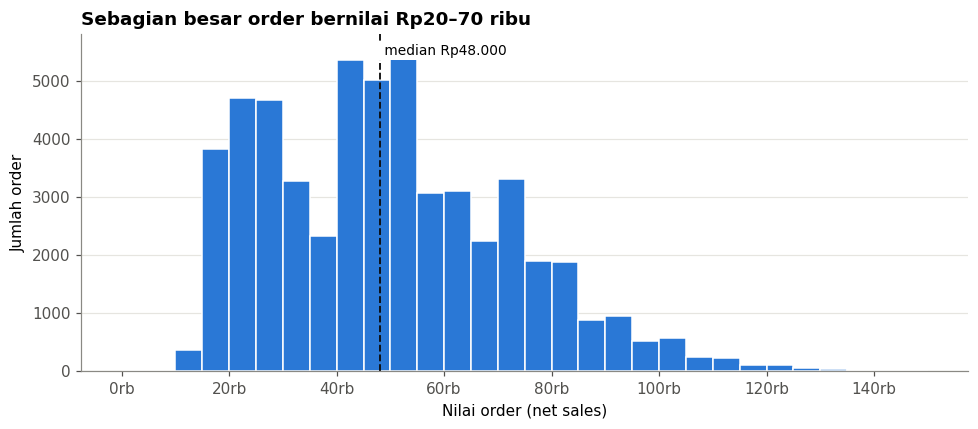

In [20]:
fig, ax = plt.subplots()
ax.hist(order_value, bins=range(0, 150_001, 5_000), color=BLUE, edgecolor="white", linewidth=1)
ax.axvline(order_value.median(), color="#0b0b0b", linestyle="--", linewidth=1.2)
ax.text(order_value.median(), ax.get_ylim()[1] * 0.97, f" median {rp(order_value.median())} ", fontsize=9,
        ha="left", va="top", bbox={"facecolor": "white", "edgecolor": "none", "pad": 1})
ax.set_title("Sebagian besar order bernilai Rp20–70 ribu")
ax.set_xlabel("Nilai order (net sales)")
ax.set_ylabel("Jumlah order")
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v / 1000:.0f}rb"))
plt.tight_layout(); plt.show()

In [21]:
S, G, T, MS = "mentah", "gabungan", "turunan", "master"
D = [
    ("sales", "order_id", "Nomor order. Satu order bisa punya banyak baris item", "teks", S, "Kunci order. Hitung order dengan COUNT DISTINCT"),
    ("sales", "order_datetime", "Waktu order dibuat", "tanggal-waktu", S, "Hanya tahun 2025; format yyyy-mm-dd hh:mm:ss"),
    ("sales", "outlet_id", "Kode outlet (SN01-SN06)", "teks", G, "Kunci penghubung ke master_outlet"),
    ("sales", "outlet", "Nama outlet", "teks", S, "Diseragamkan ke nama di master_outlet"),
    ("sales", "channel", "Cara pelanggan memesan", "kategori", S, "Dine-in, Takeaway, atau Delivery"),
    ("sales", "customer_id", "ID pelanggan; WALKIN jika bukan member", "teks", S, "Member berawalan M"),
    ("sales", "product_id", "Kode produk (P01-P15)", "teks", S, "Kunci penghubung ke master_produk"),
    ("sales", "product", "Nama produk", "teks", S, "Diambil dari master_produk"),
    ("sales", "category", "Kelompok produk", "kategori", G, "Kopi, Non-Kopi, atau Makanan"),
    ("sales", "qty", "Jumlah unit produk pada baris itu", "bilangan bulat", S, "Harus > 0; di atas 10 dianggap salah input"),
    ("sales", "unit_price", "Harga satuan (Rp)", "bilangan bulat", S, "Sama dengan harga di master_produk"),
    ("sales", "discount_amount", "Total diskon pada baris itu (Rp)", "bilangan bulat", S, "0 jika tanpa promo"),
    ("sales", "promo_name", "Nama promo", "kategori", S, "Diskon Gajian, Promo Kopi Susu Juni, atau Tanpa Promo"),
    ("sales", "is_member", "Penanda member", "label 1/0", S, "1 = member, 0 = bukan. Diseragamkan dari Ya/Y/member/Tidak/N"),
    ("sales", "gross_sales", "Penjualan sebelum diskon", "bilangan bulat", T, "qty x unit_price"),
    ("sales", "net_sales", "Penjualan setelah diskon", "bilangan bulat", T, "gross_sales - discount_amount"),
    ("sales", "cogs", "Harga pokok penjualan (HPP)", "bilangan bulat", T, "qty x cogs_per_unit dari master_produk"),
    ("sales", "delivery_commission", "Komisi platform delivery", "bilangan bulat", T, "20% dari net_sales jika channel Delivery, selain itu 0"),
    ("sales", "gross_profit", "Laba kotor", "bilangan bulat", T, "net_sales - cogs - delivery_commission"),
    ("sales", "tanggal", "Tanggal order", "teks", T, "Dari order_datetime, format yyyy-mm-dd"),
    ("sales", "bulan", "Bulan order", "teks", T, "Format yyyy-mm; urut alfabet = urut waktu"),
    ("sales", "jam", "Jam order (7-22)", "bilangan bulat", T, "Dari order_datetime"),
    ("sales", "hari", "Nama hari", "kategori", T, "Senin sampai Minggu"),
    ("sales", "is_promo", "Penanda ada promo", "label 1/0", T, "1 jika promo_name bukan Tanpa Promo"),
    ("master_outlet", "outlet_id", "Kode outlet", "teks", MS, "Kunci utama"),
    ("master_outlet", "outlet", "Nama outlet", "teks", MS, "Nama baku"),
    ("master_outlet", "kota", "Kota lokasi outlet", "teks", MS, "Jabodetabek"),
    ("master_produk", "product_id", "Kode produk", "teks", MS, "Kunci utama"),
    ("master_produk", "product", "Nama produk", "teks", MS, "Nama baku"),
    ("master_produk", "category", "Kelompok produk", "kategori", MS, "Kopi, Non-Kopi, atau Makanan"),
    ("master_produk", "price", "Harga jual (Rp)", "bilangan bulat", MS, "Harga acuan"),
    ("master_produk", "cogs_per_unit", "HPP per unit (Rp)", "bilangan bulat", MS, "Dipakai menghitung cogs"),
]
dd = pd.DataFrame(D, columns=["tabel", "kolom", "arti", "tipe", "asal", "aturan"])

# Validasi: kamus harus mencakup semua kolom nyata, tanpa kolom "hantu"
missing = set(clean.columns) - set(dd.loc[dd["tabel"] == "sales", "kolom"])
extra = set(dd.loc[dd["tabel"] == "sales", "kolom"]) - set(clean.columns)
assert not missing and not extra, f"Kamus tidak cocok: kurang {missing}, lebih {extra}"
dd.to_csv(DATA / "data_dictionary.csv", index=False)
print(f"Kamus data: {len(dd)} kolom ({(dd['asal'] == T).sum()} turunan). Cocok dengan clean_sales.csv.")
dd

Kamus data: 32 kolom (10 turunan). Cocok dengan clean_sales.csv.


,tabel,kolom,arti,tipe,asal,aturan
0,sales,order_id,Nomor order. Satu order bisa punya banyak bari...,teks,mentah,Kunci order. Hitung order dengan COUNT DISTINCT
1,sales,order_datetime,Waktu order dibuat,tanggal-waktu,mentah,Hanya tahun 2025; format yyyy-mm-dd hh:mm:ss
2,sales,outlet_id,Kode outlet (SN01-SN06),teks,gabungan,Kunci penghubung ke master_outlet
3,sales,outlet,Nama outlet,teks,mentah,Diseragamkan ke nama di master_outlet
4,sales,channel,Cara pelanggan memesan,kategori,mentah,"Dine-in, Takeaway, atau Delivery"
5,sales,customer_id,ID pelanggan; WALKIN jika bukan member,teks,mentah,Member berawalan M
6,sales,product_id,Kode produk (P01-P15),teks,mentah,Kunci penghubung ke master_produk
7,sales,product,Nama produk,teks,mentah,Diambil dari master_produk
8,sales,category,Kelompok produk,kategori,gabungan,"Kopi, Non-Kopi, atau Makanan"
9,sales,qty,Jumlah unit produk pada baris itu,bilangan bulat,mentah,Harus > 0; di atas 10 dianggap salah input


**Objek data & relasi:** tabel fakta `sales` (1 baris = 1 item dalam 1 order) terhubung ke `master_outlet`
lewat `outlet_id` dan ke `master_produk` lewat `product_id` (relasi *many-to-one*).

---
## 5. Analisis: penjualan tumbuh, di mana laba bocor?

### Definisi KPI
| KPI | Rumus |
|---|---|
| **Net sales** | qty × harga − diskon |
| **Gross profit** | net sales − HPP − komisi delivery |
| **Margin** | gross profit ÷ net sales |
| **AOV** (nilai order rata-rata) | net sales ÷ **order unik** |

> Jangan menghitung order dengan jumlah baris (`COUNT(*)`): satu order punya banyak baris item.

Semua angka hasil analisis dikumpulkan dalam dictionary `M` dan disimpan ke `metrics.json`
(dipakai di deck, dashboard, dan verifikasi SQL).

In [22]:
df = pd.read_csv(DATA / "clean_sales.csv", parse_dates=["order_datetime"])
df["tgl"] = pd.to_datetime(df["tanggal"])

def margin(g):
    return g["gross_profit"].sum() / g["net_sales"].sum()

M = {}

### 5.1 KPI utama 2025

In [23]:
orders = df["order_id"].nunique()
M["kpi"] = {
    "net_sales": int(df["net_sales"].sum()),
    "gross_profit": int(df["gross_profit"].sum()),
    "margin": margin(df),
    "orders": int(orders),
    "aov": df["net_sales"].sum() / orders,
    "total_discount": int(df["discount_amount"].sum()),
    "total_commission": int(df["delivery_commission"].sum()),
    "rows": int(len(df)),
}
k = M["kpi"]
pd.Series({
    "Net sales": rp(k["net_sales"]),
    "Gross profit": rp(k["gross_profit"]),
    "Margin": pct(k["margin"]),
    "Order unik": f"{k['orders']:,}".replace(",", "."),
    "AOV": rp(k["aov"]),
    "Total diskon": rp(k["total_discount"]),
    "Komisi delivery": rp(k["total_commission"]),
}, name="Nilai").to_frame()

,Nilai
Net sales,Rp2.664.750.400
Gross profit,Rp1.577.622.040
Margin,"59,2%"
Order unik,54.428
AOV,Rp48.959
Total diskon,Rp56.459.600
Komisi delivery,Rp151.338.060


### 5.2 Tren bulanan: penjualan naik, margin turun
Kita bandingkan semester 1 (H1: Jan–Jun) dan semester 2 (H2: Jul–Des).

In [24]:
mo = df.groupby("bulan").agg(net_sales=("net_sales", "sum"), gross_profit=("gross_profit", "sum"),
                             orders=("order_id", "nunique"))
mo["margin"] = mo["gross_profit"] / mo["net_sales"]
mo["delivery_share"] = df[df["channel"] == "Delivery"].groupby("bulan")["order_id"].nunique() / mo["orders"]
M["monthly"] = mo.to_dict("index")

h1 = df[df["order_datetime"] < "2025-07-01"]
h2 = df[df["order_datetime"] >= "2025-07-01"]
M["growth"] = {
    "net_sales_h1": int(h1["net_sales"].sum()),
    "net_sales_h2": int(h2["net_sales"].sum()),
    "net_sales_h2_vs_h1": h2["net_sales"].sum() / h1["net_sales"].sum() - 1,
    "gross_profit_h1": int(h1["gross_profit"].sum()),
    "gross_profit_h2": int(h2["gross_profit"].sum()),
    "gross_profit_h2_vs_h1": h2["gross_profit"].sum() / h1["gross_profit"].sum() - 1,
    "margin_h1": margin(h1),
    "margin_h2": margin(h2),
}
g = M["growth"]
print(f"Net sales H2 vs H1   : +{pct(g['net_sales_h2_vs_h1'])}")
print(f"Gross profit H2 vs H1: +{pct(g['gross_profit_h2_vs_h1'])}")
print(f"Margin H1 -> H2      : {pct(g['margin_h1'])} -> {pct(g['margin_h2'])}")
mo.style.format({"net_sales": "{:,.0f}", "gross_profit": "{:,.0f}", "orders": "{:,.0f}",
                 "margin": "{:.1%}", "delivery_share": "{:.1%}"})

Net sales H2 vs H1   : +28,8%
Gross profit H2 vs H1: +26,6%
Margin H1 -> H2      : 59,8% -> 58,8%


,net_sales,gross_profit,orders,margin,delivery_share
bulan,,,,,
2025-01,"183,343,100","111,060,740","3,716",60.6%,23.0%
2025-02,"170,809,800","103,457,360","3,443",60.6%,22.7%
2025-03,"194,484,800","117,707,780","3,943",60.5%,23.3%
2025-04,"196,847,800","118,343,900","3,980",60.1%,25.2%
2025-05,"214,331,400","128,557,040","4,331",60.0%,26.5%
2025-06,"204,774,500","117,125,840","4,482",57.2%,27.3%
2025-07,"227,554,800","135,065,600","4,592",59.4%,28.7%
2025-08,"246,169,100","145,328,360","4,992",59.0%,30.7%
2025-09,"237,486,700","139,590,500","4,863",58.8%,31.5%


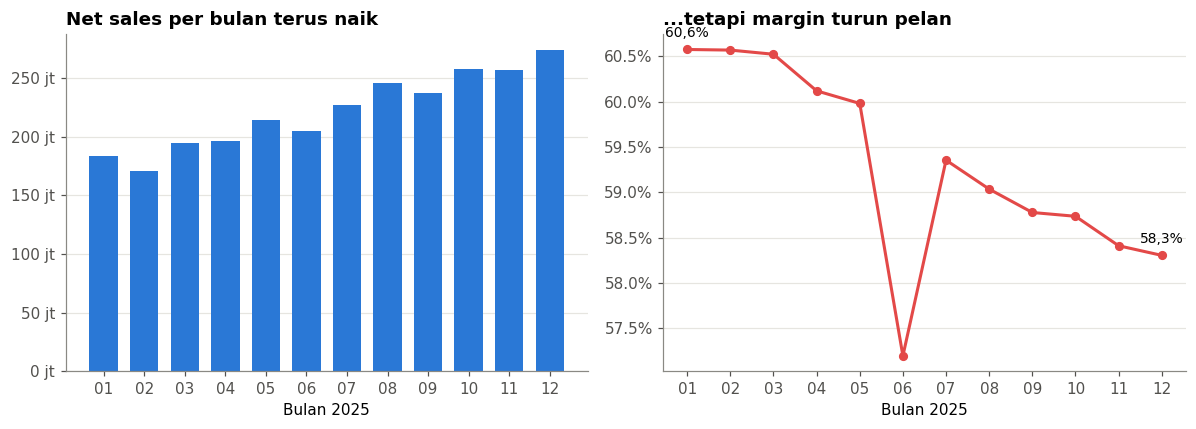

In [25]:
labels = [b[5:] for b in mo.index]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(labels, mo["net_sales"], color=BLUE, width=0.7)
axes[0].yaxis.set_major_formatter(juta_fmt)
axes[0].set_title("Net sales per bulan terus naik")
axes[0].set_xlabel("Bulan 2025")

axes[1].plot(labels, mo["margin"], color=RED, linewidth=2, marker="o", markersize=5)
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=1))
axes[1].set_title("...tetapi margin turun pelan")
axes[1].set_xlabel("Bulan 2025")
for i in (0, len(mo) - 1):
    axes[1].annotate(pct(mo["margin"].iloc[i]), (labels[i], mo["margin"].iloc[i]),
                     textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9)
plt.tight_layout(); plt.show()

**Temuan 1:** net sales H2 tumbuh lebih cepat daripada gross profit. Artinya ada biaya yang ikut membesar
lebih cepat daripada penjualan — laba "bocor" di suatu tempat. Bagian berikut mencari sumbernya.

### 5.3 Kinerja outlet

In [26]:
out = []
for name, g_ in df.groupby("outlet"):
    a, b = g_[g_["order_datetime"] < "2025-07-01"], g_[g_["order_datetime"] >= "2025-07-01"]
    out.append({
        "outlet": name,
        "net_sales": int(g_["net_sales"].sum()),
        "gross_profit": int(g_["gross_profit"].sum()),
        "margin": margin(g_),
        "orders": int(g_["order_id"].nunique()),
        "delivery_share": g_[g_["channel"] == "Delivery"]["order_id"].nunique() / g_["order_id"].nunique(),
        "growth_h2_vs_h1": b["net_sales"].sum() / a["net_sales"].sum() - 1,
    })
M["outlets"] = sorted(out, key=lambda r: -r["net_sales"])
outlet_df = pd.DataFrame(M["outlets"])
outlet_df.style.format({"net_sales": "{:,.0f}", "gross_profit": "{:,.0f}", "orders": "{:,.0f}",
                        "margin": "{:.1%}", "delivery_share": "{:.1%}", "growth_h2_vs_h1": "{:+.1%}"})

,outlet,net_sales,gross_profit,margin,orders,delivery_share,growth_h2_vs_h1
0,Seduh Nusantara Kemang,"580,772,100","343,342,780",59.1%,"11,955",29.5%,+28.1%
1,Seduh Nusantara BSD,"516,294,300","306,289,800",59.3%,"10,562",28.8%,+27.3%
2,Seduh Nusantara Summarecon Bekasi,"480,987,500","284,319,380",59.1%,"9,725",29.3%,+31.0%
3,Seduh Nusantara Margonda,"419,652,800","249,147,360",59.4%,"8,559",28.1%,+31.2%
4,Seduh Nusantara Sentul,"349,222,700","206,719,140",59.2%,"7,146",29.0%,+27.7%
5,Seduh Nusantara Kelapa Gading,"317,821,000","187,803,580",59.1%,"6,481",29.1%,+27.4%


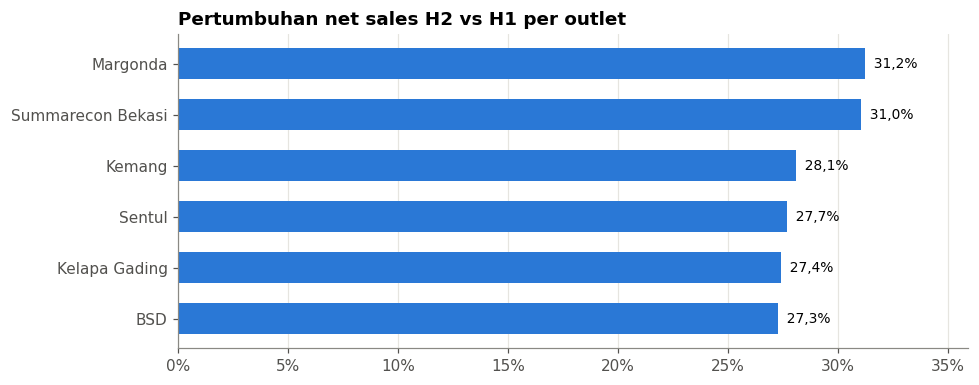

In [27]:
od = outlet_df.sort_values("growth_h2_vs_h1")
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.barh(od["outlet"].str.replace("Seduh Nusantara ", ""), od["growth_h2_vs_h1"], color=BLUE, height=0.6)
ax.xaxis.set_major_formatter(pct_fmt)
ax.set_xlim(0, od["growth_h2_vs_h1"].max() * 1.15)
ax.grid(axis="x", color="#e6e5e0"); ax.grid(axis="y", visible=False)
for y, v in enumerate(od["growth_h2_vs_h1"]):
    ax.text(v, y, f"  {pct(v)}", va="center", fontsize=9)
ax.set_title("Pertumbuhan net sales H2 vs H1 per outlet")
plt.tight_layout(); plt.show()

### 5.4 Channel: Delivery menggerus margin
Metrik channel dihitung **per order** (order unik) agar tidak terhitung ganda.

In [28]:
ch = {}
for name, g_ in df.groupby("channel"):
    n = g_["order_id"].nunique()
    ch[name] = {
        "orders": int(n),
        "share": n / orders,
        "aov": g_["net_sales"].sum() / n,
        "net_sales": int(g_["net_sales"].sum()),
        "gross_profit": int(g_["gross_profit"].sum()),
        "margin": margin(g_),
        "commission": int(g_["delivery_commission"].sum()),
        # kontribusi channel terhadap total penjualan dan total laba
        "sales_share": g_["net_sales"].sum() / df["net_sales"].sum(),
        "gp_share": g_["gross_profit"].sum() / df["gross_profit"].sum(),
    }
M["channel"] = ch
jan = df[df["bulan"] == "2025-01"]
dec = df[df["bulan"] == "2025-12"]
M["delivery_trend"] = {
    "share_jan": jan[jan["channel"] == "Delivery"]["order_id"].nunique() / jan["order_id"].nunique(),
    "share_dec": dec[dec["channel"] == "Delivery"]["order_id"].nunique() / dec["order_id"].nunique(),
    "margin_jan": margin(jan),
    "margin_dec": margin(dec),
}
pd.DataFrame(ch).T.style.format({"orders": "{:,.0f}", "share": "{:.1%}", "aov": "{:,.0f}",
                                 "net_sales": "{:,.0f}", "gross_profit": "{:,.0f}",
                                 "margin": "{:.1%}", "commission": "{:,.0f}",
                                 "sales_share": "{:.1%}", "gp_share": "{:.1%}"})

,orders,share,aov,net_sales,gross_profit,margin,commission
Delivery,"15,782",29.0%,"47,946","756,690,300","340,786,140",45.0%,"151,338,060"
Dine-in,"21,729",39.9%,"51,121","1,110,805,800","717,231,000",64.6%,0
Takeaway,"16,917",31.1%,"47,127","797,254,300","519,604,900",65.2%,0


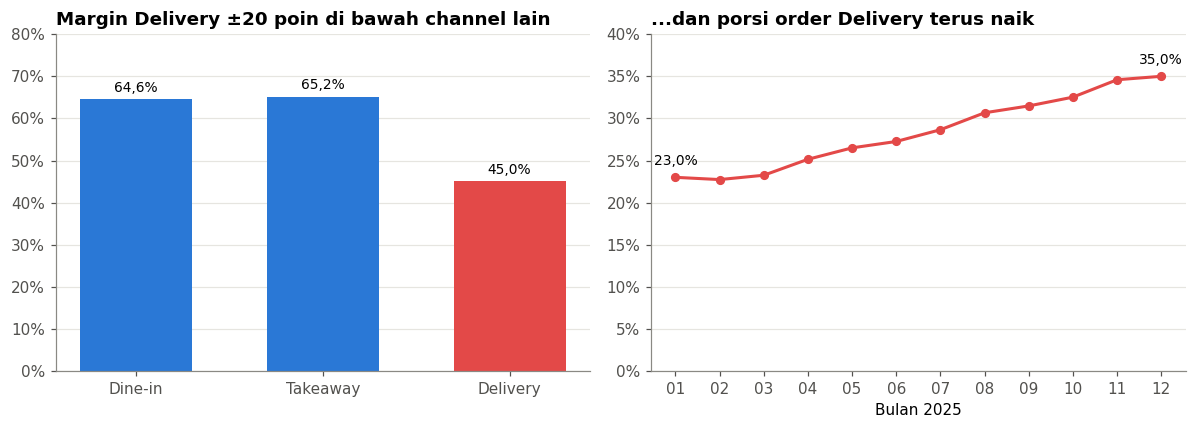

In [29]:
chan = ["Dine-in", "Takeaway", "Delivery"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
vals = [ch[c]["margin"] for c in chan]
bars = axes[0].bar(chan, vals, color=[BLUE, BLUE, RED], width=0.6)
axes[0].bar_label(bars, labels=[pct(v) for v in vals], padding=3, fontsize=9)
axes[0].yaxis.set_major_formatter(pct_fmt)
axes[0].set_ylim(0, 0.8)
axes[0].set_title("Margin Delivery ±20 poin di bawah channel lain")

axes[1].plot(labels, mo["delivery_share"], color=RED, linewidth=2, marker="o", markersize=5)
axes[1].yaxis.set_major_formatter(pct_fmt)
axes[1].set_ylim(0, 0.4)
axes[1].set_title("...dan porsi order Delivery terus naik")
axes[1].set_xlabel("Bulan 2025")
dt_ = M["delivery_trend"]
axes[1].annotate(pct(dt_["share_jan"]), (labels[0], dt_["share_jan"]), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9)
axes[1].annotate(pct(dt_["share_dec"]), (labels[-1], dt_["share_dec"]), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9)
plt.tight_layout(); plt.show()

**Temuan 2:** komisi platform 20% membuat margin Delivery jauh lebih rendah. Karena porsi order Delivery
naik dari ±23% (Jan) ke ±35% (Des), campuran channel bergeser ke channel bermargin rendah — inilah sumber
utama turunnya margin total. Delivery menyumbang ±28% penjualan, tetapi hanya ±22% laba kotor.

### 5.5 Promo

Data 2025 memuat dua promo: **Diskon Gajian** (tgl 25–27 tiap bulan, 15%) dan
**Promo Kopi Susu Juni** (35% untuk Kopi Susu Gula Aren). Tabel di bawah merangkum keduanya,
tetapi analisis mendalam difokuskan pada **Promo Kopi Susu Juni**: diskon besar pada satu produk
yang dampaknya ke laba paling jelas terlihat.

In [30]:
pr = []
for name, g_ in df.groupby("promo_name"):
    pr.append({
        "promo": name,
        "discount": int(g_["discount_amount"].sum()),
        "net_sales": int(g_["net_sales"].sum()),
        "gross_profit": int(g_["gross_profit"].sum()),
        "margin": margin(g_),
        "orders": int(g_["order_id"].nunique()),
    })
M["promo"] = sorted(pr, key=lambda r: -r["discount"])
pd.DataFrame(M["promo"]).style.format({"discount": "{:,.0f}", "net_sales": "{:,.0f}",
                                       "gross_profit": "{:,.0f}", "margin": "{:.1%}", "orders": "{:,.0f}"})

,promo,discount,net_sales,gross_profit,margin,orders
0,Diskon Gajian,"40,813,200","231,274,800","124,477,120",53.8%,"5,487"
1,Promo Kopi Susu Juni,"15,646,400","29,057,600","12,221,720",42.1%,"1,779"
2,Tanpa Promo,0,"2,404,418,000","1,440,923,200",59.9%,"48,504"


#### 5.5a Promo Kopi Susu Juni: unit naik, laba turun

In [33]:
ks = df[df["product"] == "Kopi Susu Gula Aren"]

def ks_month(m):
    g_ = ks[ks["bulan"] == m]
    units = int(g_["qty"].sum())
    return {"units": units, "net_sales": int(g_["net_sales"].sum()), "gross_profit": int(g_["gross_profit"].sum()),
            "gp_per_unit": g_["gross_profit"].sum() / units, "discount": int(g_["discount_amount"].sum())}

may, jun = ks_month("2025-05"), ks_month("2025-06")
M["kopi_susu"] = {
    "mei": may,
    "juni": jun,
    "unit_change": jun["units"] / may["units"] - 1,
    "gp_change": jun["gross_profit"] / may["gross_profit"] - 1,
    "gp_lost": may["gross_profit"] - jun["gross_profit"],
    "units_needed_to_match_may": may["gross_profit"] / jun["gp_per_unit"],
}
pd.DataFrame({"Mei": may, "Juni": jun}).style.format("{:,.0f}")

,Mei,Juni
units,"1,756","2,032"
net_sales,"38,104,000","29,057,600"
gross_profit,"22,894,380","12,221,720"
gp_per_unit,"13,038","6,015"
discount,"528,000","15,646,400"


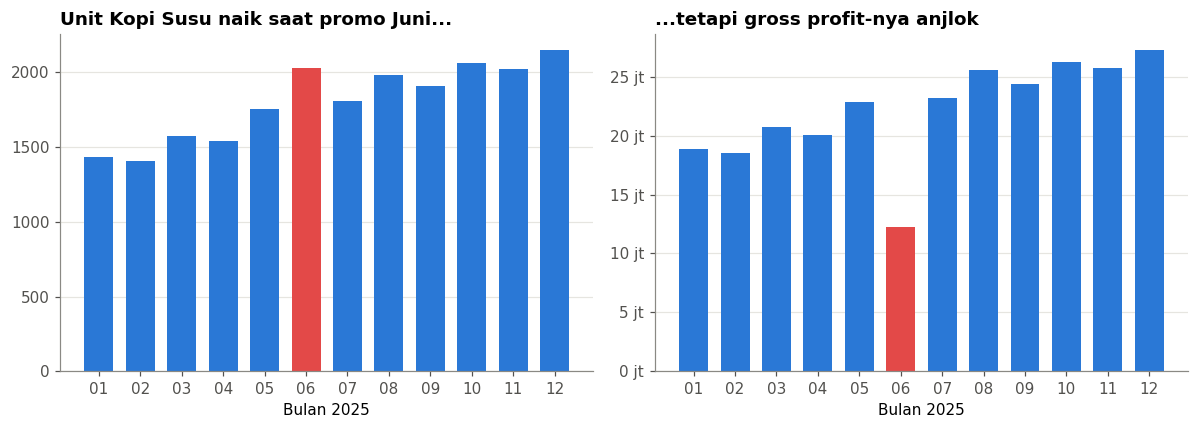

Unit 15,7% | gross profit -46,6% | laba hilang Rp10,7 jt
Unit yang dibutuhkan agar laba Juni = Mei: 3.806


In [34]:
ksm = ks.groupby("bulan").agg(units=("qty", "sum"), gp=("gross_profit", "sum"))
colors = [RED if b == "2025-06" else BLUE for b in ksm.index]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(labels, ksm["units"], color=colors, width=0.7)
axes[0].set_title("Unit Kopi Susu naik saat promo Juni...")
axes[0].set_xlabel("Bulan 2025")
axes[1].bar(labels, ksm["gp"], color=colors, width=0.7)
axes[1].yaxis.set_major_formatter(juta_fmt)
axes[1].set_title("...tetapi gross profit-nya anjlok")
axes[1].set_xlabel("Bulan 2025")
plt.tight_layout(); plt.show()

kk = M["kopi_susu"]
print(f"Unit {pct(kk['unit_change'])} | gross profit {pct(kk['gp_change'])} | laba hilang {rp(kk['gp_lost'], juta=True)}")
print(f"Unit yang dibutuhkan agar laba Juni = Mei: {kk['units_needed_to_match_may']:,.0f}".replace(",", "."))

**Temuan 3:** diskon 35% terlalu dalam. Volume memang naik, tetapi laba per unit turun lebih tajam,
sehingga total laba produk ini justru turun hampir separuh.

### 5.6 Produk (makanan) dan member
- **Food attach rate** = persentase order yang berisi minimal satu makanan.
- **Retensi member 60 hari** = persentase member yang order lagi ≤ 60 hari setelah order pertamanya.
  Hanya member yang order pertamanya ≥ 60 hari sebelum 31 Des yang dihitung (*eligible*), agar adil.

In [35]:
og = df.groupby("order_id").agg(net=("net_sales", "sum"), gp=("gross_profit", "sum"),
                                food=("category", lambda s: (s == "Makanan").any()),
                                channel=("channel", "first"))
food_gp = df[df["category"] == "Makanan"].groupby("order_id")["gross_profit"].sum()
M["food"] = {
    "attach": float(og["food"].mean()),
    "aov_with_food": float(og.loc[og["food"], "net"].mean()),
    "aov_without_food": float(og.loc[~og["food"], "net"].mean()),
    "avg_food_gp_per_food_order": float(food_gp.mean()),
    "attach_by_channel": {c: float(og.loc[og["channel"] == c, "food"].mean()) for c in ["Dine-in", "Takeaway", "Delivery"]},
}
cat = df.groupby("category").agg(net_sales=("net_sales", "sum"), gross_profit=("gross_profit", "sum"))
cat["margin"] = cat["gross_profit"] / cat["net_sales"]
M["category"] = cat.reset_index().to_dict("records")

fm = M["food"]
print(f"Food attach rate         : {pct(fm['attach'])}")
print(f"AOV dengan makanan       : {rp(fm['aov_with_food'])}")
print(f"AOV tanpa makanan        : {rp(fm['aov_without_food'])}")
print("Attach per channel       :", {c: pct(v) for c, v in fm["attach_by_channel"].items()})
cat.style.format({"net_sales": "{:,.0f}", "gross_profit": "{:,.0f}", "margin": "{:.1%}"})

Food attach rate         : 33,8%
AOV dengan makanan       : Rp66.219
AOV tanpa makanan        : Rp40.156
Attach per channel       : {'Dine-in': '41,6%', 'Takeaway': '27,0%', 'Delivery': '30,3%'}


,net_sales,gross_profit,margin
category,,,
Kopi,"1,297,852,000","789,993,700",60.9%
Makanan,"485,738,400","251,453,980",51.8%
Non-Kopi,"881,160,000","536,174,360",60.8%


In [36]:
mem = df[df["is_member"] == 1].drop_duplicates("order_id")[["order_id", "customer_id", "tgl"]]
first = mem.groupby("customer_id")["tgl"].min().rename("first")
mem = mem.merge(first, on="customer_id")
later = mem[(mem["tgl"] > mem["first"]) & (mem["tgl"] <= mem["first"] + pd.Timedelta(days=60))]
returned = set(later["customer_id"])
elig = first[first <= pd.Timestamp("2025-12-31") - pd.Timedelta(days=60)]
ret_rate = elig.index.isin(returned).mean()
early = elig[elig < "2025-07-01"]
late = elig[elig >= "2025-07-01"]
M["member"] = {
    "members": int(df.loc[df["is_member"] == 1, "customer_id"].nunique()),
    "member_order_share": float(df.loc[df["is_member"] == 1, "order_id"].nunique() / orders),
    "eligible": int(len(elig)),
    "return_60d": float(ret_rate),
    "return_60d_cohort_h1": float(early.index.isin(returned).mean()),
    "return_60d_cohort_h2": float(late.index.isin(returned).mean()),
    "eligible_h1": int(len(early)),
    "eligible_h2": int(len(late)),
}
mm = M["member"]
print(f"Member: {mm['members']:,} | porsi order member: {pct(mm['member_order_share'])}".replace(",", "."))
print(f"Retensi 60 hari: {pct(mm['return_60d'])} dari {mm['eligible']:,} member eligible".replace(",", "."))
print(f"Kohort H1 {pct(mm['return_60d_cohort_h1'])} vs kohort H2 {pct(mm['return_60d_cohort_h2'])}")

Member: 2.000 | porsi order member: 35.0%
Retensi 60 hari: 79.9% dari 1.785 member eligible
Kohort H1 80,8% vs kohort H2 77,5%


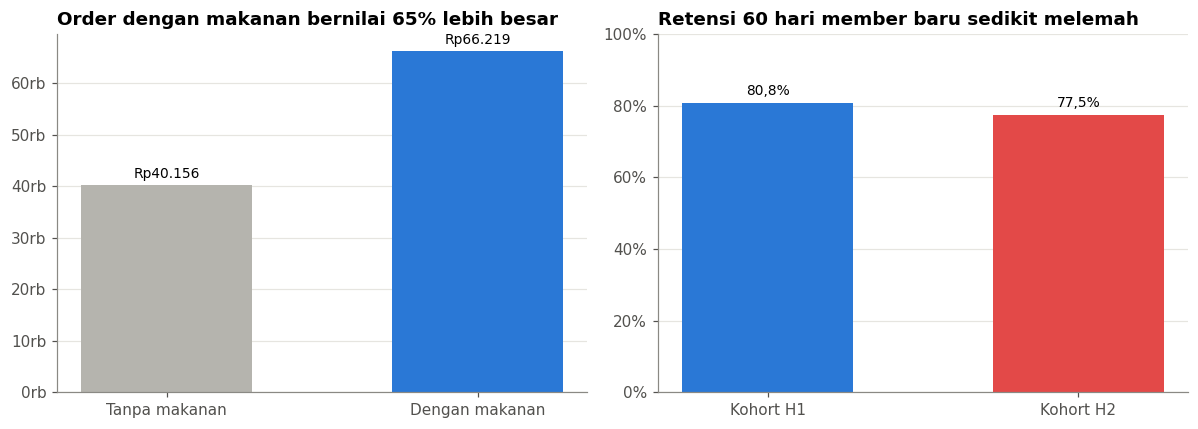

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
v = [fm["aov_without_food"], fm["aov_with_food"]]
b = axes[0].bar(["Tanpa makanan", "Dengan makanan"], v, color=[GRAY, BLUE], width=0.55)
axes[0].bar_label(b, labels=[rp(x) for x in v], padding=3, fontsize=9)
axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x / 1000:.0f}rb"))
axes[0].set_title(f"Order dengan makanan bernilai {pct(v[1] / v[0] - 1, 0)} lebih besar")

v = [mm["return_60d_cohort_h1"], mm["return_60d_cohort_h2"]]
b = axes[1].bar(["Kohort H1", "Kohort H2"], v, color=[BLUE, RED], width=0.55)
axes[1].bar_label(b, labels=[pct(x) for x in v], padding=3, fontsize=9)
axes[1].yaxis.set_major_formatter(pct_fmt)
axes[1].set_ylim(0, 1)
axes[1].set_title("Retensi 60 hari member baru sedikit melemah")
plt.tight_layout(); plt.show()

**Temuan 4:** hanya sekitar sepertiga order berisi makanan, padahal order dengan makanan bernilai jauh lebih
besar. Retensi member tinggi, tetapi kohort yang bergabung di H2 sedikit lebih rendah — dibaca sebagai
**arah**, bukan kepastian (kohort awal memuat member lama yang memang lebih aktif).

---
## 6. Estimasi dampak rekomendasi

Setiap estimasi memakai asumsi sederhana yang ditulis jelas. Angka-angka ini **tidak dijumlahkan**
karena asumsinya berbeda dan sebagian tumpang tindih.

| Kode | Rekomendasi | Asumsi |
|---|---|---|
| R1 | Atur harga delivery: naikkan harga menu di aplikasi 5% | Volume tetap, komisi tetap 20% |
| R2 | Batasi diskon besar (contoh: Kopi Susu Juni), ganti dengan paket/bundle | Selisih laba Juni vs Mei |
| R3 | *(tambahan)* Naikkan food attach rate 5 poin (bundling) | Pembeli tambahan membeli makanan seperti rata-rata |

In [38]:
dl = df[df["channel"] == "Delivery"]
price_up = 0.05
gain_r1 = dl["net_sales"].sum() * price_up * (1 - COMMISSION)
M["impact"] = {
    "delivery_price_up_pct": price_up,
    "delivery_price_up_gain": float(gain_r1),
    # titik impas: order delivery boleh turun sekian persen sebelum laba delivery lebih rendah dari sekarang
    "delivery_price_up_breakeven_drop": float(gain_r1 / (dl["gross_profit"].sum() + gain_r1)),
    # selisih margin delivery vs dine-in, dikali net sales delivery = "laba yang bocor" di channel ini
    "delivery_margin_gap_loss": float(dl["net_sales"].sum() * (ch["Dine-in"]["margin"] - ch["Delivery"]["margin"])),
    "kopi_susu_gp_lost": M["kopi_susu"]["gp_lost"],
    "food_attach_up_pts": 0.05,
    "food_attach_gain": float(0.05 * orders * M["food"]["avg_food_gp_per_food_order"]),
}
im = M["impact"]
pd.DataFrame([
    ("R1", "Harga delivery +5%", rp(im["delivery_price_up_gain"], juta=True),
     f"Impas jika order delivery turun ≤ {pct(im['delivery_price_up_breakeven_drop'])}"),
    ("R2", "Batasi diskon besar", rp(im["kopi_susu_gp_lost"], juta=True), "Laba hilang per promo serupa (Kopi Susu Juni vs Mei)"),
    ("R3", "Food attach +5 poin", rp(im["food_attach_gain"], juta=True), "Lewat bundling minuman + makanan"),
], columns=["Kode", "Rekomendasi", "Estimasi tambahan laba/tahun", "Catatan"])

,Kode,Rekomendasi,Estimasi tambahan laba/tahun,Catatan
0,R1,Harga delivery +5%,"Rp30,3 jt","Impas jika order delivery turun ≤ 8,2%"
1,R2,Evaluasi Diskon Gajian,"Rp40,8 jt",Batas atas (order dianggap tidak turun)
2,R3,Perkecil diskon Kopi Susu,"Rp10,7 jt",Laba yang hilang Juni vs Mei
3,R4,Food attach +5 poin,"Rp37,2 jt",Lewat bundling minuman + makanan


In [39]:
# Simpan semua metrik
with open(DATA / "metrics.json", "w", encoding="utf-8") as f:
    json.dump(M, f, ensure_ascii=False, indent=2, default=float)
print("metrics.json tersimpan:", (DATA / "metrics.json").relative_to(ROOT))

metrics.json tersimpan: data\metrics.json


---
## 7. Verifikasi silang dengan SQL

Untuk memvalidasi hasil analisis, 10 query di `sql/analysis_queries.sql` dijalankan pada database
`seduh.db`, lalu hasilnya dibandingkan dengan angka pandas di `metrics.json`. Jika ada selisih,
`assert` akan menghentikan notebook dengan pesan error.

In [40]:
con = sqlite3.connect(DATA / "seduh.db")
text = (ROOT / "sql" / "analysis_queries.sql").read_text(encoding="utf-8")
blocks = re.split(r"^-- Query (\d+):.*$", text, flags=re.M)
queries = {int(blocks[i]): blocks[i + 1] for i in range(1, len(blocks), 2)}
titles = dict(re.findall(r"^-- Query (\d+): (.*)$", text, flags=re.M))
assert sorted(queries) == list(range(1, 11)), "Harus ada 10 query"

def run(n):
    return pd.read_sql_query(queries[n], con)

for n in queries:
    print(f"Query {n}: {titles[str(n)]}")

Query 1: KPI utama
Query 2: Tren bulanan (net sales, gross profit, margin, order)
Query 3: Kinerja outlet dan pertumbuhan H2 vs H1
Query 4: Channel (hitung per order dulu supaya order tidak terhitung ganda)
Query 5: Porsi order Delivery per bulan, dan margin Delivery vs non-Delivery
Query 6: Ringkasan per promo
Query 7: Diskon Gajian, order per hari kerja (Senin-Jumat): hari Gajian vs lainnya
Query 8: Kopi Susu Gula Aren, Mei vs Juni (unit naik, laba turun)
Query 9: Food attach rate dan nilai order dengan vs tanpa makanan
Query 10: Retensi member, kembali order dalam <= 60 hari setelah order pertama


Contoh: hasil **Query 4** (channel) — perhatikan CTE `o` yang menjumlahkan per order dulu
agar order tidak terhitung ganda.

In [41]:
print(queries[4].strip())
run(4)

WITH o AS (
  SELECT order_id, channel, SUM(net_sales) AS net, SUM(gross_profit) AS gp
  FROM sales
  GROUP BY order_id, channel
)
SELECT
  channel,
  COUNT(*)                                            AS orders,
  ROUND(1.0 * COUNT(*) / (SELECT COUNT(*) FROM o), 4) AS share,
  ROUND(AVG(net), 0)                                  AS aov,
  ROUND(1.0 * SUM(gp) / SUM(net), 4)                  AS margin
FROM o
GROUP BY channel
ORDER BY orders DESC;


,channel,orders,share,aov,margin
0,Dine-in,21729,0.3992,51121.0,0.6457
1,Takeaway,16917,0.3108,47127.0,0.6517
2,Delivery,15782,0.2900,47946.0,0.4504


In [42]:
def close(a, b, tol=1e-4, label=""):
    ok = abs(float(a) - float(b)) <= tol * max(1.0, abs(float(b)))
    assert ok, f"BEDA {label}: SQL={a} pandas={b}"

checks = 0
Mj = json.load(open(DATA / "metrics.json", encoding="utf-8"))

# Q1 KPI utama
r = run(1).iloc[0]; k = Mj["kpi"]
for col, tol in (("net_sales", 1e-4), ("gross_profit", 1e-4), ("orders", 1e-4),
                 ("margin", 1e-3), ("aov", 1e-3), ("total_discount", 1e-4)):
    close(r[col], k[col], tol, f"Q1 {col}"); checks += 1

# Q2 tren bulanan
for _, r in run(2).iterrows():
    m = Mj["monthly"][r["bulan"]]
    close(r["net_sales"], m["net_sales"], label=f"Q2 {r['bulan']} net")
    close(r["orders"], m["orders"], label=f"Q2 {r['bulan']} orders")
    close(r["margin"], m["margin"], 1e-3, f"Q2 {r['bulan']} margin")
    checks += 3

# Q3 outlet
by_outlet = {o_["outlet"]: o_ for o_ in Mj["outlets"]}
for _, r in run(3).iterrows():
    o_ = by_outlet[r["outlet"]]
    close(r["net_sales"], o_["net_sales"], label=f"Q3 {r['outlet']} net")
    close(r["growth_h2_vs_h1"], o_["growth_h2_vs_h1"], 1e-3, f"Q3 {r['outlet']} growth")
    checks += 2

# Q4 channel
for _, r in run(4).iterrows():
    c = Mj["channel"][r["channel"]]
    close(r["orders"], c["orders"], label=f"Q4 {r['channel']} orders")
    close(r["share"], c["share"], 1e-3, f"Q4 {r['channel']} share")
    close(r["aov"], c["aov"], 1e-3, f"Q4 {r['channel']} aov")
    close(r["margin"], c["margin"], 1e-3, f"Q4 {r['channel']} margin")
    checks += 4

# Q5 porsi delivery per bulan
q5 = run(5)
for _, r in q5.iterrows():
    close(r["delivery_share"], Mj["monthly"][r["bulan"]]["delivery_share"], 1e-3, f"Q5 {r['bulan']} share")
    checks += 1
close(q5.iloc[0]["delivery_share"], Mj["delivery_trend"]["share_jan"], 1e-3, "Q5 share Jan")
close(q5.iloc[-1]["delivery_share"], Mj["delivery_trend"]["share_dec"], 1e-3, "Q5 share Des")
checks += 2

# Q6 promo
by_promo = {p["promo"]: p for p in Mj["promo"]}
for _, r in run(6).iterrows():
    p = by_promo[r["promo_name"]]
    close(r["discount"], p["discount"], label=f"Q6 {r['promo_name']} discount")
    close(r["orders"], p["orders"], label=f"Q6 {r['promo_name']} orders")
    close(r["margin"], p["margin"], 1e-3, f"Q6 {r['promo_name']} margin")
    checks += 3

# Q7 kontribusi channel terhadap penjualan dan laba
for _, r in run(7).iterrows():
    c = Mj["channel"][r["channel"]]
    close(r["net_sales"], c["net_sales"], label=f"Q7 {r['channel']} net")
    close(r["sales_share"], c["sales_share"], 1e-3, f"Q7 {r['channel']} porsi penjualan")
    close(r["gp_share"], c["gp_share"], 1e-3, f"Q7 {r['channel']} porsi laba")
    checks += 3

# Q8 Kopi Susu
rows8 = run(8).set_index("bulan")
for key, bulan in (("mei", "2025-05"), ("juni", "2025-06")):
    close(rows8.loc[bulan, "units"], Mj["kopi_susu"][key]["units"], label=f"Q8 {key} units")
    close(rows8.loc[bulan, "gross_profit"], Mj["kopi_susu"][key]["gross_profit"], label=f"Q8 {key} gp")
    checks += 2

# Q9 food attach
rows9 = run(9).set_index("has_food")
close(rows9.loc[1, "share"], Mj["food"]["attach"], 1e-3, "Q9 attach")
close(rows9.loc[1, "aov"], Mj["food"]["aov_with_food"], 1e-3, "Q9 aov makanan")
close(rows9.loc[0, "aov"], Mj["food"]["aov_without_food"], 1e-3, "Q9 aov tanpa makanan")
checks += 3

# Q10 retensi member
r = run(10).iloc[0]
close(r["eligible_members"], Mj["member"]["eligible"], label="Q10 eligible")
close(r["return_60d"], Mj["member"]["return_60d"], 1e-3, "Q10 retensi")
checks += 2

con.close()
print(f"OK: 10 query SQL cocok dengan pandas ({checks} angka dibandingkan).")

OK: 10 query SQL cocok dengan pandas (101 angka dibandingkan).


---
## 8. Kesimpulan, rekomendasi, dan batasan

Sel di bawah merangkum angka kunci langsung dari hasil analisis, sehingga ringkasan selalu sesuai dengan data.

In [43]:
k, g, c, kk, fm, mm = M["kpi"], M["growth"], M["channel"], M["kopi_susu"], M["food"], M["member"]
ringkasan = pd.DataFrame([
    ("Penjualan tumbuh, laba tertinggal",
     f"Net sales H2 +{pct(g['net_sales_h2_vs_h1'])}, gross profit +{pct(g['gross_profit_h2_vs_h1'])}; "
     f"margin {pct(g['margin_h1'])} → {pct(g['margin_h2'])}"),
    ("Delivery menggerus margin",
     f"Margin Delivery {pct(c['Delivery']['margin'])} vs Dine-in {pct(c['Dine-in']['margin'])}; "
     f"porsi order {pct(M['delivery_trend']['share_jan'])} → {pct(M['delivery_trend']['share_dec'])}; "
     f"komisi {rp(k['total_commission'], juta=True)}; "
     f"porsi penjualan {pct(c['Delivery']['sales_share'])} vs porsi laba {pct(c['Delivery']['gp_share'])}"),
    ("Promo menambah volume, bukan laba",
     f"Kopi Susu Mei → Juni: unit +{pct(kk['unit_change'])}, gross profit {pct(kk['gp_change'])}; "
     f"laba hilang {rp(kk['gp_lost'], juta=True)}"),
    ("Makanan = peluang menaikkan nilai order",
     f"Attach {pct(fm['attach'])}; AOV {rp(fm['aov_with_food'])} (dengan) vs {rp(fm['aov_without_food'])} (tanpa)"),
    ("Retensi member tinggi, kohort baru melemah",
     f"Retensi 60 hari {pct(mm['return_60d'])}; kohort H1 {pct(mm['return_60d_cohort_h1'])} vs H2 {pct(mm['return_60d_cohort_h2'])}"),
], columns=["Temuan", "Bukti angka"])
ringkasan.style.hide(axis="index").set_properties(**{"text-align": "left"})

Temuan,Bukti angka
"Penjualan tumbuh, laba tertinggal","Net sales H2 +28,8%, gross profit +26,6%; margin 59,8% → 58,8%"
Delivery menggerus margin,"Margin Delivery 45,0% vs Dine-in 64,6%; porsi order 23,0% → 35,0%; komisi Rp151,3 jt"
Diskon Gajian belum terbukti efektif,"Order/hari kerja +3,1% (p = 0.37); laba tambahan ±Rp3,8 jt vs biaya diskon Rp40,8 jt"
Promo Kopi Susu terlalu dalam,"Unit 15,7%, gross profit -46,6% (Mei → Juni)"
Makanan = peluang menaikkan nilai order,"Attach 33,8%; AOV Rp66.219 (dengan) vs Rp40.156 (tanpa)"
"Retensi member tinggi, kohort baru melemah","Retensi 60 hari 79,9%; kohort H1 80,8% vs H2 77,5%"


### Rekomendasi
1. **Atur harga delivery (R1):** naikkan harga menu di aplikasi delivery 5% untuk menutup komisi 20%,
   dan dorong pelanggan memesan langsung (takeaway / pre-order) lewat program member.
2. **Batasi diskon besar (R2):** hindari diskon sebesar 35% pada satu produk; ganti dengan paket (bundle)
   yang menjaga laba per unit, dan selalu hitung titik impas unit sebelum promo dijalankan.

Rekomendasi tambahan (tidak dimasukkan ke deck):
- **Makanan (R3):** buat paket bundling minuman + makanan, terutama di channel Takeaway dan Delivery yang attach rate-nya rendah.
- **Member:** pantau retensi kohort baru setiap bulan dan beri insentif kunjungan kedua.

### Batasan analisis
- Data **simulasi**: pola sengaja dirancang, jadi hasilnya bukan fakta pasar.
- Perbandingan Kopi Susu Mei vs Juni adalah **perbandingan sederhana**, bukan eksperimen terkontrol.
- *Diskon Gajian* ada di data tetapi tidak dianalisis tersendiri; efeknya tetap terhitung di KPI total.
- Estimasi dampak memakai asumsi volume tetap dan **tidak boleh dijumlahkan**.
- Retensi kohort H2 punya jendela pengamatan lebih pendek dan kohort H1 memuat member lama yang lebih aktif —
  selisihnya dibaca sebagai arah.
- Biaya operasional (sewa, gaji, listrik) tidak tersedia, jadi analisis berhenti di **gross profit**.

### File keluaran
| File | Isi |
|---|---|
| `data/raw_sales.csv` | Data mentah (sengaja kotor) |
| `data/clean_sales.csv` | Data bersih untuk Looker Studio / Power BI |
| `data/data_quality_log.csv` | Log 25 langkah cleaning |
| `data/seduh.db` | Database SQLite (sales, master_outlet, master_produk) |
| `data/data_profile.csv`, `data/data_summary.json` | Profil data & statistik deskriptif |
| `data/data_dictionary.csv` | Kamus data 32 kolom |
| `data/metrics.json` | Semua angka hasil analisis |